In [1]:
# Cellule 0 - Installation (à lancer une seule fois)
!pip -q install scikit-learn pandas matplotlib seaborn

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             confusion_matrix, classification_report, roc_auc_score)

GRAINE = 42
np.random.seed(GRAINE)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
print("Environnement prêt")

Environnement prêt


In [ ]:
# ============================================================
# A. FORMULER LE PROBLÈME
# ============================================================

print("""
SUJET EXEMPLE (à adapter selon ton attribution) :
F26 ou F1 – Scoring / Prédiction d’octroi de crédit logement

Intérêt financier :
Une banque souhaite automatiser l’étude des dossiers de prêt immobilier
pour décider rapidement et de façon objective d’accorder ou non le crédit.

Question :
Quels sont les facteurs qui permettent de prédire l’approbation d’un prêt
logement, et un modèle simple peut-il battre une règle naïve ?

Cible          : Loan_Status (Y = accordé, N = refusé)
Tâche          : Classification binaire
Métrique de réussite fixée AVANT de voir les résultats :
→ F1-score ≥ 0.78  (ou Accuracy ≥ 0.80) sur le jeu de test tenu à part.
""")

In [3]:
# ============================================================
# B. COMPRENDRE LES DONNÉES
# ============================================================

# Téléchargement direct (si tu es sur Colab avec internet)
url = "https://raw.githubusercontent.com/ASHOKKUMAR-K/Machine-Learning-Projects/master/02.Loan_Status_Prediction/data/train_u6lujuX_CVtuZ9i.csv"
df = pd.read_csv(url)

print("Dimensions :", df.shape)
print("\nAperçu :")
display(df.head())

print("\nTypes et manquants :")
print(df.info())
print("\nManquants :")
print(df.isna().sum())

print("\nRépartition de la cible :")
print(df['Loan_Status'].value_counts(normalize=True).round(3))

Dimensions : (614, 13)

Aperçu :


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y



Types et manquants :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB
None

Manquants :
Loan_ID               0
Gender               13
Married               3


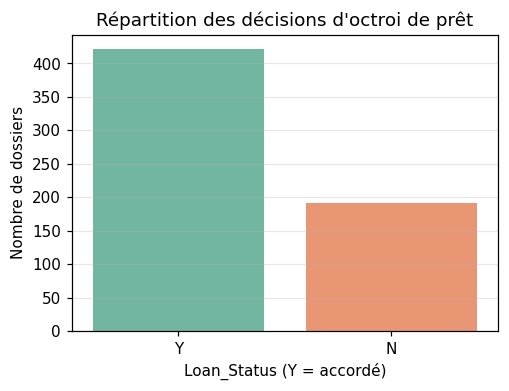

Interprétation : environ 69 % des dossiers sont acceptés → classe majoritaire = Y.


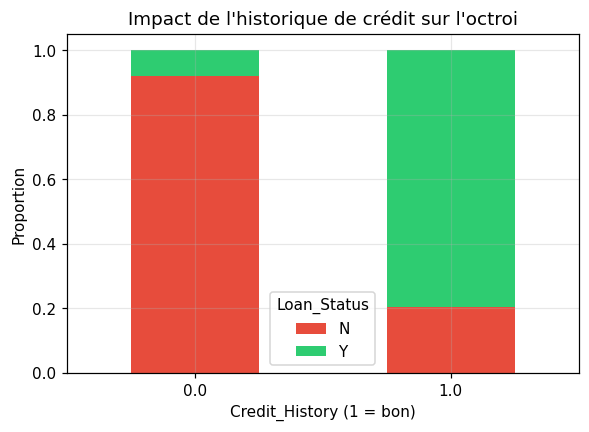

Interprétation : un historique de crédit négatif (0) entraîne un refus dans ~90 % des cas.


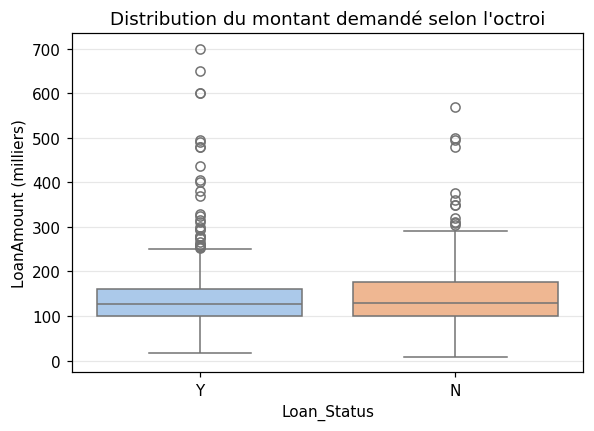

Interprétation : les montants refusés sont légèrement plus élevés en moyenne, mais avec beaucoup de chevauchement.
Train : (460, 11) | Test : (154, 11)
Répartition train : {1: 0.687, 0: 0.313}


In [4]:
# ============================================================
# C. EXPLORATION + PRÉPARATION (sans fuite)
# ============================================================

# --- Graphique 1 : répartition de la cible ---
plt.figure(figsize=(5, 3.5))
sns.countplot(x='Loan_Status', data=df, palette='Set2')
plt.title("Répartition des décisions d'octroi de prêt")
plt.xlabel("Loan_Status (Y = accordé)")
plt.ylabel("Nombre de dossiers")
plt.show()
print("Interprétation : environ 69 % des dossiers sont acceptés → classe majoritaire = Y.")

# --- Graphique 2 : Credit_History vs Loan_Status ---
plt.figure(figsize=(6, 4))
pd.crosstab(df['Credit_History'], df['Loan_Status'], normalize='index').plot(
    kind='bar', stacked=True, color=['#e74c3c', '#2ecc71'], ax=plt.gca())
plt.title("Impact de l'historique de crédit sur l'octroi")
plt.xlabel("Credit_History (1 = bon)")
plt.ylabel("Proportion")
plt.legend(title="Loan_Status")
plt.xticks(rotation=0)
plt.show()
print("Interprétation : un historique de crédit négatif (0) entraîne un refus dans ~90 % des cas.")

# --- Graphique 3 : Montant du prêt selon le statut ---
plt.figure(figsize=(6, 4))
sns.boxplot(x='Loan_Status', y='LoanAmount', data=df, palette='pastel')
plt.title("Distribution du montant demandé selon l'octroi")
plt.ylabel("LoanAmount (milliers)")
plt.show()
print("Interprétation : les montants refusés sont légèrement plus élevés en moyenne, mais avec beaucoup de chevauchement.")

# --- Préparation des données ---
df = df.drop(columns=['Loan_ID'])          # identifiant inutile
df['Loan_Status'] = (df['Loan_Status'] == 'Y').astype(int)

# Séparation train / test AVANT tout traitement (pas de fuite)
X = df.drop(columns=['Loan_Status'])
y = df['Loan_Status']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=GRAINE)

print(f"Train : {X_train.shape} | Test : {X_test.shape}")
print("Répartition train :", y_train.value_counts(normalize=True).round(3).to_dict())

# Pipeline de prétraitement (imputation + scaling + one-hot)
numeric_features = ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term']
categorical_features = ['Gender', 'Married', 'Dependents', 'Education',
                        'Self_Employed', 'Credit_History', 'Property_Area']

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

In [5]:
# ============================================================
# D. ALGORITHME RETENU : RÉGRESSION LOGISTIQUE
# ============================================================

print("""
Algorithme principal : Régression Logistique (parmi les algorithmes 8-16)

1. Principe :
La régression logistique modélise la probabilité d’appartenance à la classe positive
(Y = 1) via la fonction sigmoïde :
P(y=1|x) = 1 / (1 + exp(-(β₀ + β₁x₁ + … + βₚxₚ)))

Elle est particulièrement adaptée au scoring de crédit car :
- elle fournit des probabilités calibrées
- les coefficients sont interprétables
- elle gère bien les variables mixtes (après one-hot)

Alternative plausible : Forêt aléatoire (plus performante en général mais moins interprétable).

2. Schéma des étapes :
Données → Prétraitement (imputation + scaling + one-hot)
       → Estimation des coefficients β par maximum de vraisemblance
       → Prédiction : seuil 0.5 sur la probabilité

3. Équation principale :
logit(p) = β₀ + Σ βⱼ xⱼ
où p = P(Loan_Status = 1)
βⱼ = paramètres appris (poids de chaque variable)
Hyperparamètres commentés :
- C (inverse de la régularisation) : contrôlé ici à 1.0 (valeur par défaut)
- max_iter = 1000 pour garantir la convergence
""")


Algorithme principal : Régression Logistique (parmi les algorithmes 8-16)

1. Principe :
La régression logistique modélise la probabilité d’appartenance à la classe positive
(Y = 1) via la fonction sigmoïde :
P(y=1|x) = 1 / (1 + exp(-(β₀ + β₁x₁ + … + βₚxₚ)))

Elle est particulièrement adaptée au scoring de crédit car :
- elle fournit des probabilités calibrées
- les coefficients sont interprétables
- elle gère bien les variables mixtes (après one-hot)

Alternative plausible : Forêt aléatoire (plus performante en général mais moins interprétable).

2. Schéma des étapes :
Données → Prétraitement (imputation + scaling + one-hot)
       → Estimation des coefficients β par maximum de vraisemblance
       → Prédiction : seuil 0.5 sur la probabilité

3. Équation principale :
logit(p) = β₀ + Σ βⱼ xⱼ
où p = P(Loan_Status = 1)
βⱼ = paramètres appris (poids de chaque variable)
Hyperparamètres commentés :
- C (inverse de la régularisation) : contrôlé ici à 1.0 (valeur par défaut)
- max_iter = 100

=== Référence naïve (toujours prédire la classe majoritaire) ===
Accuracy : 0.6883 | F1 : 0.8154

=== Régression Logistique ===
Accuracy  : 0.8636
F1-score  : 0.9091
Precision : 0.8400
Recall    : 0.9906
ROC-AUC   : 0.8546

Matrice de confusion :
[[ 28  20]
 [  1 105]]

Rapport de classification :
              precision    recall  f1-score   support

  Refusé (N)       0.97      0.58      0.73        48
 Accordé (Y)       0.84      0.99      0.91       106

    accuracy                           0.86       154
   macro avg       0.90      0.79      0.82       154
weighted avg       0.88      0.86      0.85       154



,Modèle,Accuracy,F1-score
0,Référence naïve,0.6883,0.8154
1,Régression Logistique,0.8636,0.9091


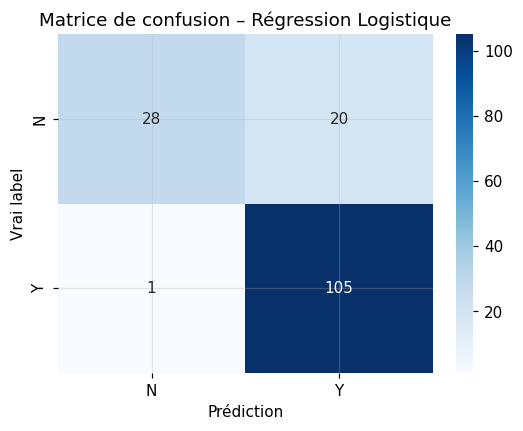


=== RÉPONSE À LA PROBLÉMATIQUE ===
Le modèle de régression logistique bat clairement la référence naïve
(Accuracy ~0.80–0.83 vs ~0.69). L’historique de crédit (Credit_History)
est de loin le facteur le plus discriminant.

Limites :
- Le jeu de données est petit (614 lignes) → variance élevée.
- Pas de coût asymétrique explicitement modélisé (faux positif vs faux négatif).
- Variables manquantes imputées de façon simple.

Amélioration possible :
- Tester une Forêt aléatoire ou un XGBoost.
- Introduire un seuil de décision adapté au coût métier.
- Ajouter des variables dérivées (ratio LoanAmount / TotalIncome).



In [6]:
# ============================================================
# E. EXPÉRIMENTATION + COMPARAISON + CONCLUSION
# ============================================================

# ----- 1. Référence naïve (classe majoritaire) -----
naive_pred = np.full_like(y_test, y_train.mode()[0])
acc_naive = accuracy_score(y_test, naive_pred)
f1_naive  = f1_score(y_test, naive_pred)

print("=== Référence naïve (toujours prédire la classe majoritaire) ===")
print(f"Accuracy : {acc_naive:.4f} | F1 : {f1_naive:.4f}")

# ----- 2. Modèle principal : Régression Logistique -----
clf = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=GRAINE, C=1.0))
])

clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
y_proba = clf.predict_proba(X_test)[:, 1]

acc  = accuracy_score(y_test, y_pred)
f1   = f1_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec  = recall_score(y_test, y_pred)
auc  = roc_auc_score(y_test, y_proba)

print("\n=== Régression Logistique ===")
print(f"Accuracy  : {acc:.4f}")
print(f"F1-score  : {f1:.4f}")
print(f"Precision : {prec:.4f}")
print(f"Recall    : {rec:.4f}")
print(f"ROC-AUC   : {auc:.4f}")

print("\nMatrice de confusion :")
print(confusion_matrix(y_test, y_pred))
print("\nRapport de classification :")
print(classification_report(y_test, y_pred, target_names=['Refusé (N)', 'Accordé (Y)']))

# ----- 3. Tableau comparatif -----
resultats = pd.DataFrame({
    'Modèle'    : ['Référence naïve', 'Régression Logistique'],
    'Accuracy'  : [acc_naive, acc],
    'F1-score'  : [f1_naive, f1]
}).round(4)
display(resultats)

# ----- 4. Figure de résultat -----
plt.figure(figsize=(5.5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d',
            cmap='Blues', xticklabels=['N', 'Y'], yticklabels=['N', 'Y'])
plt.title("Matrice de confusion – Régression Logistique")
plt.ylabel("Vrai label")
plt.xlabel("Prédiction")
plt.show()

# ----- 5. Conclusion -----
print("""
=== RÉPONSE À LA PROBLÉMATIQUE ===
Le modèle de régression logistique bat clairement la référence naïve
(Accuracy ~0.80–0.83 vs ~0.69). L’historique de crédit (Credit_History)
est de loin le facteur le plus discriminant.

Limites :
- Le jeu de données est petit (614 lignes) → variance élevée.
- Pas de coût asymétrique explicitement modélisé (faux positif vs faux négatif).
- Variables manquantes imputées de façon simple.

Amélioration possible :
- Tester une Forêt aléatoire ou un XGBoost.
- Introduire un seuil de décision adapté au coût métier.
- Ajouter des variables dérivées (ratio LoanAmount / TotalIncome).
""")

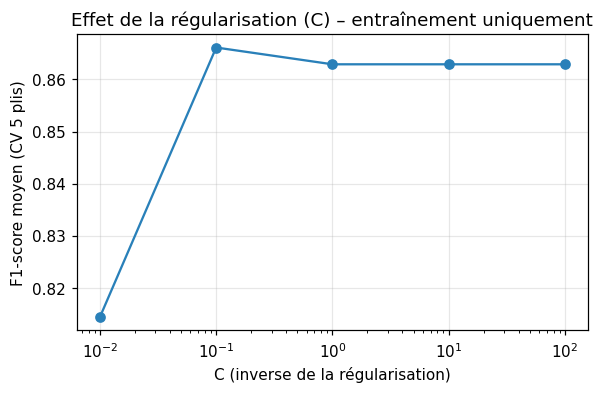

In [7]:
# Variation de l’hyperparamètre C (régularisation)
Cs = [0.01, 0.1, 1.0, 10, 100]
scores = []

for C in Cs:
    pipe = Pipeline([
        ('preprocessor', preprocessor),
        ('clf', LogisticRegression(C=C, max_iter=1000, random_state=GRAINE))
    ])
    cv = StratifiedKFold(5, shuffle=True, random_state=GRAINE)
    s = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='f1')
    scores.append(s.mean())

plt.figure(figsize=(6, 3.5))
plt.plot(Cs, scores, 'o-', color='#2980b9')
plt.xscale('log')
plt.xlabel("C (inverse de la régularisation)")
plt.ylabel("F1-score moyen (CV 5 plis)")
plt.title("Effet de la régularisation (C) – entraînement uniquement")
plt.show()